In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

How does network connectivity shape transcriptional plasticity across environments in E. coli?

**Regulatory network connectivity**: in-degree of the target gene$$k_g = |\{TF_i: TF_i \rightarrow g\}|$$

**Transcriptional plasticity**: How much expression change of a gene across the environments. /How the gene enpression deviates from the base line under this environmental change. The total plasticity of a gene is the average of E among all the conditions. For this dataset, the normalization of tpm is already set the average of references 0, so this step is not necessary.
$$\Delta E_{gene,condition}=\overline{\log_2 TPM}_{gene,condition}-(\overline{\log_2 TPM}_{gene,\text{reference}})\\
P_{gene,envirs}=\frac{1}{N_{envir}}\sum_{condition\in envirs}|\Delta E_{gene,condition}|$$

**Coordination**: How snychronized of the expression between the hub and parnters $$C_i = \frac{1}{N(i)}\sum_{j\in N(i)} corr(x_i, x_j)$$

## Conclusion

Genes with higher regulatory in-degree tend to exhibit higher transcriptional plasticity across diverse environmental perturbations.

## prepareation

In [ ]:
iModulons = pd.read_csv("iModulons.csv", header=0)
modulon_dict = {
    modulon: set(iModulons.loc[iModulons[modulon] == 1, iModulons.columns[0]])
    for modulon in iModulons.columns[1:]
}  # iModulon: (genes)

gene_modulon_dict = {
    row[iModulons.columns[0]]: {
        modulon
        for modulon in iModulons.columns[1:]
        if row[modulon] == 1
    }
    for _, row in iModulons.iterrows()
    if row[iModulons.columns[1:]].sum() > 0
}# gene: (iMoludons it involves)

{'b0001': {'Resistance'},
 'b0002': {'Leu/Val/Ile'},
 'b0003': {'Leu/Val/Ile'},
 'b0004': {'Leu/Val/Ile'},
 'b0005': {'UC-4'},
 'b0014': {'RpoH'},
 'b0015': {'RpoH'},
 'b0023': {'UC-9'},
 'b0031': {'Lysine/T2SS'},
 'b0032': {'Arginine', 'Pyrimidine'},
 'b0033': {'Arginine', 'Pyrimidine'},
 'b0034': {'Pyrimidine'},
 'b0042': {'Phosphate'},
 'b0057': {'UC-8'},
 'b0060': {'DNA Damage'},
 'b0061': {'Arabinose'},
 'b0062': {'Arabinose'},
 'b0063': {'Arabinose'},
 'b0068': {'Thiamine'},
 'b4662': {'Fucose', 'Phosphate', 'Resistance', 'ldrD'},
 'b0071': {'Leucine/Dipeptide', 'Lrp-2'},
 'b0072': {'Leucine/Dipeptide', 'Lrp-2'},
 'b0073': {'Leucine/Dipeptide', 'Lrp-2'},
 'b0074': {'Leucine/Dipeptide', 'Lrp-2'},
 'b0075': {'Lrp-2', 'Resistance'},
 'b0076': {'Lrp-2'},
 'b0084': {'Resistance'},
 'b0086': {'UC-5'},
 'b0112': {'TyrR'},
 'b0113': {'ArcA-2'},
 'b0114': {'ArcA-2', 'SG_17'},
 'b0115': {'ArcA-2'},
 'b0116': {'ArcA-2'},
 'b0118': {'ArcA-2'},
 'b0123': {'Copper'},
 'b0124': {'ArcA-2'},
 'b0

In [2]:
tpm = pd.read_csv("precise_mg1655-log_tpm.csv", header=0)
samples = pd.read_csv("precise_mg1655-sample_table.csv", header=0)

def filter_tpm_by_metadata(filtered_metadata, tpm_table = tpm):
    """
    Filter TPM expression table using unique_identifier
    from a filtered metadata dataframe.

    Parameters
    ----------
    filtered_metadata : pd.DataFrame
        Filtered sample metadata containing unique_identifier.

    tpm_table : pd.DataFrame
        Gene expression table:
        rows = genes
        columns = sample unique_identifiers.

    Returns
    -------
    pd.DataFrame
        TPM table containing gene_id + selected samples.
    """

    # Get filtered sample IDs
    sample_ids = (filtered_metadata["unique_identifier"].tolist())

    # Keep only IDs that actually exist in TPM table
    valid_ids = [sample_id for sample_id in sample_ids if sample_id in tpm_table.columns
    ]

    # Check missing IDs
    missing_ids = [sample_id for sample_id in sample_ids if sample_id not in tpm_table.columns]

    if missing_ids:
        print("Warning: IDs not found in TPM table:")
        print(missing_ids)

    # first column = gene_id, rest columns = selected samples
    gene_col = tpm_table.columns[0]

    # gene_id + selected samples
    filtered_tpm = tpm_table[[gene_col] + valid_ids].copy()
    filtered_tpm = filtered_tpm.set_index(gene_col)
    return filtered_tpm

## in-degree and coordination
targets = [all targets id]

up_regulate_dic = target: (regulators)

In [3]:
trns = pd.read_csv("precise_mg1655-trn.csv", sep=",", header=0)
trn_clean = trns[
    trns["regulator_id"].notna() &
    trns["evidence"].notna() &
    trns["target_id"].notna()
]
# evidence: Weak-0, Strong-1, Confirmed-2
# remove all NaN in regulator_id, target_id, evidence

In [5]:
# the regulators of targets, ignore the self-regulation
targets = trn_clean["target_id"].unique()
up_regulate_dic = {} # target: (upstream regulators)
for target in targets:
    regulators = set(trn_clean[trn_clean["target_id"] == target]["regulator_id"].unique())
    if target in regulators:
        regulators.remove(target)
    up_regulate_dic[target] = regulators
#up_regulate_dic

In [6]:
plasticity_total = pd.DataFrame({"gene_id": tpm["gene_id"]})
plasticity_total = plasticity_total.set_index("gene_id")
coordination_total = pd.DataFrame({"gene_id": tpm["gene_id"]})
coordination_total = coordination_total.set_index("gene_id")

plasticity_total["indegree"] = np.nan
coordination_total["indegree"] = np.nan

for target in targets:
    degree = len(up_regulate_dic[target])
    plasticity_total.loc[target, "indegree"] = degree
    coordination_total.loc[target, "indegree"] = degree

## carbon_df

SNPv1, \<C Source\>_NH4Cl, reference_condition_identifier: pmg_wt_77;pmg_wt_78

82 samples - 41 conditions, 2 replicates each

In [9]:
def construct_palsiticity_coordination(df, targets=targets, regulation_dict = up_regulate_dic):
    df_tpm = filter_tpm_by_metadata(df, tpm) 
    # log tpm is already the distance away from the reference

    #Plasticity
    plasticity = df_tpm.abs().mean(axis=1)

    #Coordinate
    coordination = pd.Series(np.nan, index=df_tpm.index, name="coordination")
    for target in targets:
        if target not in df_tpm.index:
            continue
        regulators = regulation_dict[target]
        correlations = []
        for reg in regulators:
            reg_exp = df_tpm.loc[reg].values
            target_exp = df_tpm.loc[target].values
            corr = np.corrcoef(reg_exp, target_exp)[0, 1]
            if not np.isnan(corr):
                correlations.append(np.abs(corr))
        if len(correlations) > 0:
            coordination.loc[target] = np.mean(correlations)
    return plasticity, coordination

In [10]:
# carbon_df
carbon_df = samples[
    (samples["project"] == "SNPv1")
    & (samples["condition"].str.endswith("_NH4Cl", na=False))
].copy()

carbon_plasticity, carbon_coordination = construct_palsiticity_coordination(carbon_df)
plasticity_total["carbon_plasticity"] = carbon_plasticity
coordination_total["carbon_coordination"] = carbon_coordination

c:\ProgramData\miniconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\ProgramData\miniconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


## nitrogen_df
SNPv1, Glucose_\<N Source\>, reference: pmg_wt_77;pmg_wt_78

In [11]:
# nitrogen_df
nitrogen_df = samples[
    (samples["project"] == "SNPv1")
    & (samples["condition"].str.startswith(("Glucose_", "D-Glucose_"), na=False))
].copy()

nitrogen_plasticity, nitrogen_coordination = construct_palsiticity_coordination(nitrogen_df)
plasticity_total["nitrogen_plasticity"] = nitrogen_plasticity
coordination_total["nitrogen_coordination"] = nitrogen_coordination

c:\ProgramData\miniconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\ProgramData\miniconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


## supplement_df
Glucose_NH4Cl with supplements

In [12]:
supplement_df = samples[(samples["project"] == "SNPv2")].copy()

supplement_plasticity, supplement_coordination = construct_palsiticity_coordination(supplement_df)

plasticity_total["supplement_plasticity"] = supplement_plasticity
coordination_total["supplement_coordination"] = supplement_coordination

c:\ProgramData\miniconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\ProgramData\miniconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


## Antibiotic exposure
Antibiotics(4+1): meropenem(mero), trimethoprim-sulfamethoxazole(trisulf), ceftriaxone(cef), ciprofloxacin(cipro), control(ctrl)

Mediums(3): M9(m9), RPMI+10%LB(rpmi), CAMHB(camhb)

In [13]:
# antibiotic exposure

abx_media_df = samples[(samples["project_name"] == "AntibiotICA")].copy()

# M9 media
abx_m9_df = abx_media_df[abx_media_df["condition"].str.startswith("m9_", na=False)].copy()

abx_m9_plasticity, abx_m9_coordination = construct_palsiticity_coordination(abx_m9_df)

plasticity_total["abx_m9_plasticity"] = abx_m9_plasticity
coordination_total["abx_m9_coordination"] = abx_m9_coordination

c:\ProgramData\miniconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\ProgramData\miniconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


## stationary TRN
How is the TRN reorgnized when E. coli enters the stationary phase due to the depletion of different nutrients?

 C/N/S starvation, timeline: C3, C4, C5, N3, N4, N5, N8, N12, S4, S8, S12 (hours)

In [14]:
# stationary TRN
stationary_trn_df = samples[(samples["project_name"] == "stationary-TRN")].copy()

stationary_trn_plasticity, stationary_trn_coordination = construct_palsiticity_coordination(stationary_trn_df)

plasticity_total["stationary_trn_plasticity"] = stationary_trn_plasticity
coordination_total["stationary_trn_coordination"] = stationary_trn_coordination

c:\ProgramData\miniconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\ProgramData\miniconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


## plot and regression

In [15]:
import statsmodels.api as sm

In [16]:
plasticity_clean = plasticity_total.dropna()
plasticity_clean.to_csv("plasticity_clean.csv", index=True)

In [17]:
coordination_clean = coordination_total.dropna()
coordination_clean.to_csv("coordination_clean.csv", index=True)

In [21]:
plasticity_clean = pd.read_csv("plasticity_clean.csv").set_index("gene_id")
coordination_clean = pd.read_csv("coordination_clean.csv").set_index("gene_id")

In [22]:
conditions = ["carbon", "nitrogen", "supplement", "abx_m9", "stationary_trn"]

def plot_regression(condition, clean_df, varibale):
    # variable = plasticity or coordination
    colunm_name = condition + "_" + varibale
    X = clean_df["indegree"]
    y = clean_df[colunm_name]
    plt.scatter(X, y, alpha=0.1)
    reg_model = sm.OLS(y, sm.add_constant(X)).fit()
    plt.plot(X, reg_model.predict(sm.add_constant(X)), color='red', linewidth=2)
    plt.xlabel("in-degree")
    plt.ylabel(colunm_name)
    plt.show()
    print("Slope:", reg_model.params[1])

    return reg_model

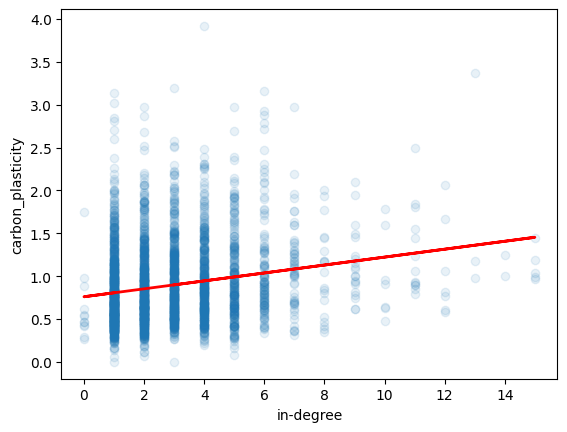

Slope: 0.04622258475680358
                            OLS Regression Results                            
Dep. Variable:      carbon_plasticity   R-squared:                       0.040
Model:                            OLS   Adj. R-squared:                  0.039
Method:                 Least Squares   F-statistic:                     121.7
Date:                Sat, 03 Oct 2026   Prob (F-statistic):           9.53e-28
Time:                        23:28:27   Log-Likelihood:                -1840.6
No. Observations:                2946   AIC:                             3685.
Df Residuals:                    2944   BIC:                             3697.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.7599    

C:\Users\24776\AppData\Local\Temp\ipykernel_11192\3686025141.py:14: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print("Slope:", reg_model.params[1])


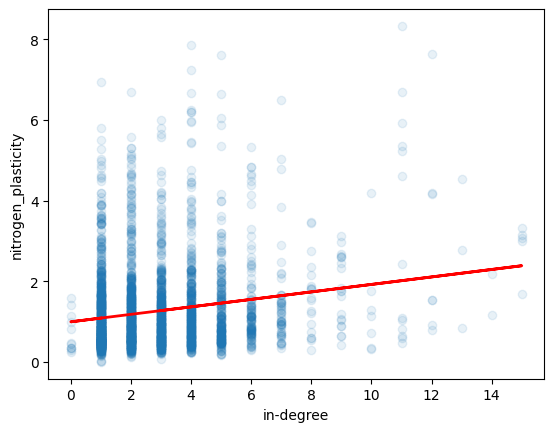

Slope: 0.09266984903997114
                             OLS Regression Results                            
Dep. Variable:     nitrogen_plasticity   R-squared:                       0.032
Model:                             OLS   Adj. R-squared:                  0.031
Method:                  Least Squares   F-statistic:                     96.02
Date:                 Sat, 03 Oct 2026   Prob (F-statistic):           2.49e-22
Time:                         23:28:28   Log-Likelihood:                -4238.4
No. Observations:                 2946   AIC:                             8481.
Df Residuals:                     2944   BIC:                             8493.
Df Model:                            1                                         
Covariance Type:             nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          

C:\Users\24776\AppData\Local\Temp\ipykernel_11192\3686025141.py:14: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print("Slope:", reg_model.params[1])


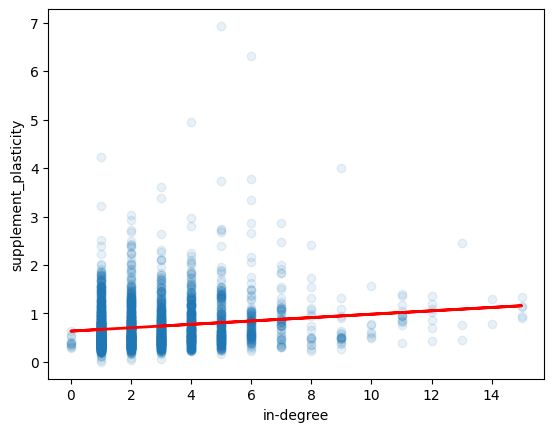

C:\Users\24776\AppData\Local\Temp\ipykernel_11192\3686025141.py:14: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print("Slope:", reg_model.params[1])


Slope: 0.03489505655664929
                              OLS Regression Results                             
Dep. Variable:     supplement_plasticity   R-squared:                       0.021
Model:                               OLS   Adj. R-squared:                  0.021
Method:                    Least Squares   F-statistic:                     63.58
Date:                   Sat, 03 Oct 2026   Prob (F-statistic):           2.18e-15
Time:                           23:28:28   Log-Likelihood:                -1968.1
No. Observations:                   2946   AIC:                             3940.
Df Residuals:                       2944   BIC:                             3952.
Df Model:                              1                                         
Covariance Type:               nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------

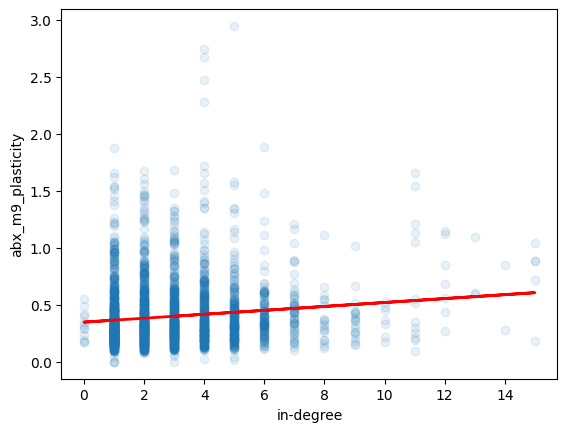

C:\Users\24776\AppData\Local\Temp\ipykernel_11192\3686025141.py:14: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print("Slope:", reg_model.params[1])


Slope: 0.01722800467241741
                            OLS Regression Results                            
Dep. Variable:      abx_m9_plasticity   R-squared:                       0.016
Model:                            OLS   Adj. R-squared:                  0.016
Method:                 Least Squares   F-statistic:                     47.53
Date:                Sat, 03 Oct 2026   Prob (F-statistic):           6.61e-12
Time:                        23:28:28   Log-Likelihood:                -317.54
No. Observations:                2946   AIC:                             639.1
Df Residuals:                    2944   BIC:                             651.1
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.3490    

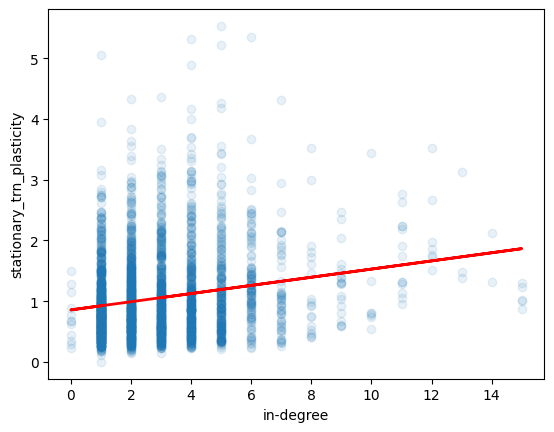

Slope: 0.06720722174955013
                                OLS Regression Results                               
Dep. Variable:     stationary_trn_plasticity   R-squared:                       0.039
Model:                                   OLS   Adj. R-squared:                  0.039
Method:                        Least Squares   F-statistic:                     119.0
Date:                       Sat, 03 Oct 2026   Prob (F-statistic):           3.39e-27
Time:                               23:28:28   Log-Likelihood:                -2975.4
No. Observations:                       2946   AIC:                             5955.
Df Residuals:                           2944   BIC:                             5967.
Df Model:                                  1                                         
Covariance Type:                   nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------

C:\Users\24776\AppData\Local\Temp\ipykernel_11192\3686025141.py:14: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print("Slope:", reg_model.params[1])


In [23]:
# Plasticity
for condition in conditions:
    model = f"{condition}_model"
    model = plot_regression(condition, plasticity_clean, "plasticity")
    print(model.summary())
# All slopes are significant

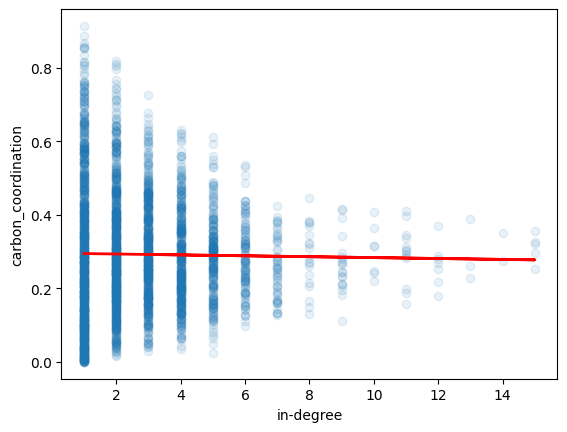

Slope: -0.0012240275379340154
                             OLS Regression Results                            
Dep. Variable:     carbon_coordination   R-squared:                       0.000
Model:                             OLS   Adj. R-squared:                 -0.000
Method:                  Least Squares   F-statistic:                    0.6566
Date:                 Sat, 03 Oct 2026   Prob (F-statistic):              0.418
Time:                         23:28:31   Log-Likelihood:                 1172.2
No. Observations:                 2930   AIC:                            -2340.
Df Residuals:                     2928   BIC:                            -2328.
Df Model:                            1                                         
Covariance Type:             nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       

C:\Users\24776\AppData\Local\Temp\ipykernel_11192\3686025141.py:14: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print("Slope:", reg_model.params[1])


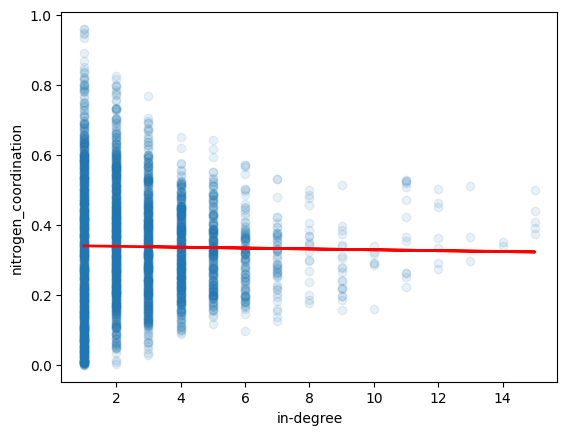

Slope: -0.0012417315628033185
                              OLS Regression Results                             
Dep. Variable:     nitrogen_coordination   R-squared:                       0.000
Model:                               OLS   Adj. R-squared:                 -0.000
Method:                    Least Squares   F-statistic:                    0.6244
Date:                   Sat, 03 Oct 2026   Prob (F-statistic):              0.429
Time:                           23:28:32   Log-Likelihood:                 1056.3
No. Observations:                   2930   AIC:                            -2109.
Df Residuals:                       2928   BIC:                            -2097.
Df Model:                              1                                         
Covariance Type:               nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------

C:\Users\24776\AppData\Local\Temp\ipykernel_11192\3686025141.py:14: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print("Slope:", reg_model.params[1])


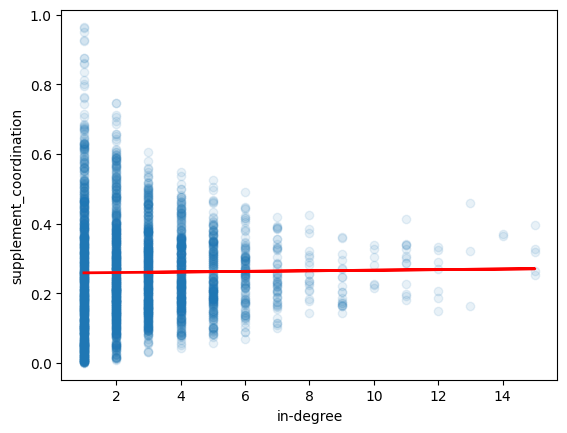

C:\Users\24776\AppData\Local\Temp\ipykernel_11192\3686025141.py:14: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print("Slope:", reg_model.params[1])


Slope: 0.0008379583796989974
                               OLS Regression Results                              
Dep. Variable:     supplement_coordination   R-squared:                       0.000
Model:                                 OLS   Adj. R-squared:                 -0.000
Method:                      Least Squares   F-statistic:                    0.3726
Date:                     Sat, 03 Oct 2026   Prob (F-statistic):              0.542
Time:                             23:28:32   Log-Likelihood:                 1452.5
No. Observations:                     2930   AIC:                            -2901.
Df Residuals:                         2928   BIC:                            -2889.
Df Model:                                1                                         
Covariance Type:                 nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------

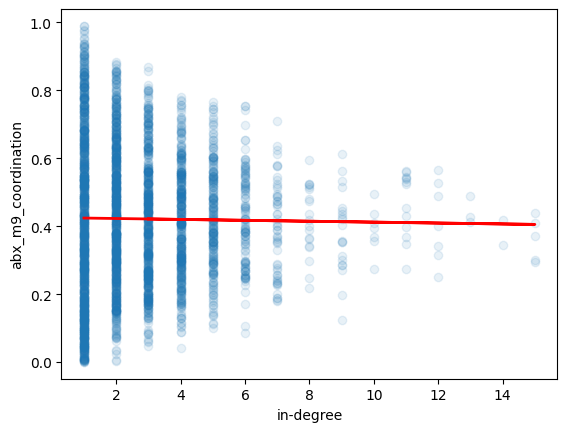

C:\Users\24776\AppData\Local\Temp\ipykernel_11192\3686025141.py:14: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print("Slope:", reg_model.params[1])


Slope: -0.001336930554535373
                             OLS Regression Results                            
Dep. Variable:     abx_m9_coordination   R-squared:                       0.000
Model:                             OLS   Adj. R-squared:                 -0.000
Method:                  Least Squares   F-statistic:                    0.4937
Date:                 Sat, 03 Oct 2026   Prob (F-statistic):              0.482
Time:                         23:28:32   Log-Likelihood:                 495.81
No. Observations:                 2930   AIC:                            -987.6
Df Residuals:                     2928   BIC:                            -975.7
Df Model:                            1                                         
Covariance Type:             nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        

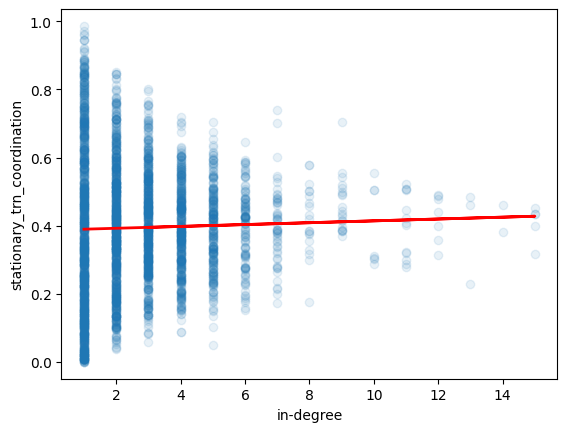

Slope: 0.0027190863139275063
                                 OLS Regression Results                                
Dep. Variable:     stationary_trn_coordination   R-squared:                       0.001
Model:                                     OLS   Adj. R-squared:                  0.000
Method:                          Least Squares   F-statistic:                     2.422
Date:                         Sat, 03 Oct 2026   Prob (F-statistic):              0.120
Time:                                 23:28:32   Log-Likelihood:                 745.60
No. Observations:                         2930   AIC:                            -1487.
Df Residuals:                             2928   BIC:                            -1475.
Df Model:                                    1                                         
Covariance Type:                     nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------

C:\Users\24776\AppData\Local\Temp\ipykernel_11192\3686025141.py:14: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print("Slope:", reg_model.params[1])


In [24]:
# Coordination
for condition in conditions:
    model = f"{condition}_model"
    model = plot_regression(condition, coordination_clean, "coordination")
    print(model.summary())
# All slopes are significant

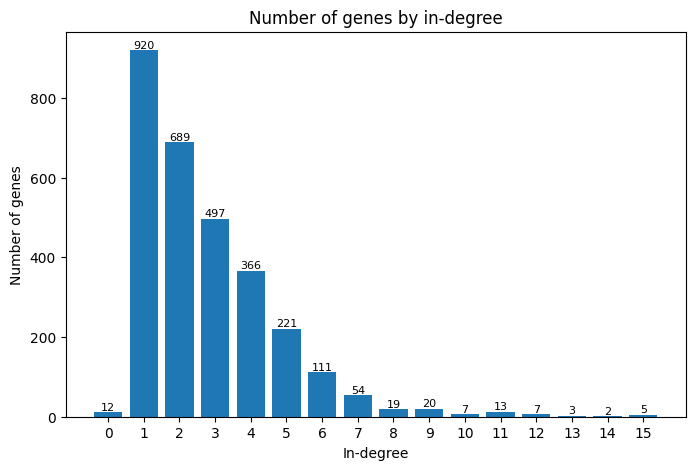

In [25]:
degree_counts = plasticity_clean["indegree"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

bars = plt.bar(
    degree_counts.index,
    degree_counts.values
)

plt.xlabel("In-degree")
plt.ylabel("Number of genes")
plt.title("Number of genes by in-degree")

for x, n in zip(degree_counts.index, degree_counts.values):
    plt.text(
        x,
        n,
        str(n),
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.xticks(degree_counts.index)
plt.show()

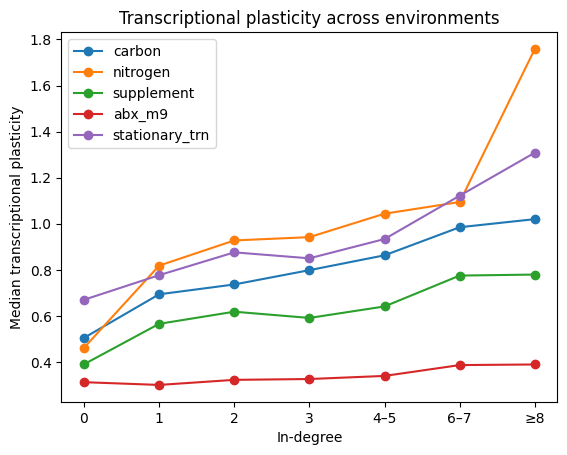

In [26]:
# plasticity medians

bins = [-0.5, 0.5, 1.5, 2.5, 3.5, 5.5, 7.5, np.inf]
labels = ["0", "1", "2", "3", "4–5", "6–7", "≥8"]

plasticity_clean["degree_group"] = pd.cut(
    plasticity_clean["indegree"],
    bins=bins,
    labels=labels
)

plasticity_cols = [
    col for col in plasticity_clean.columns
    if col.endswith("_plasticity")
]

#plt.figure(figsize=(8, 6))

for col in plasticity_cols:

    median_values = (
        plasticity_clean
        .groupby("degree_group", observed=True)[col]
        .median()
    )

    plt.plot(
        median_values.index.astype(str),
        median_values.values,
        marker="o",
        label=col.replace("_plasticity", "")
    )

#plt.axvline(x=8, linestyle="--", color="black")
plt.xlabel("In-degree")
plt.ylabel("Median transcriptional plasticity")
plt.title("Transcriptional plasticity across environments")
plt.legend()
plt.show()

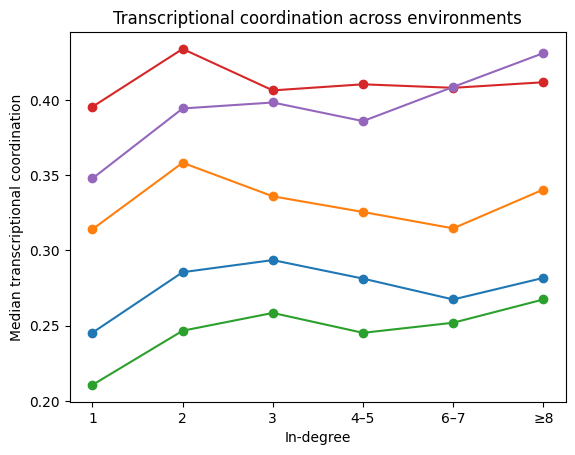

In [39]:
# coordination medians

bins = [-0.5, 0.5, 1.5, 2.5, 3.5, 5.5, 7.5, np.inf]
labels = ["0", "1", "2", "3", "4–5", "6–7", "≥8"]

coordination_clean["degree_group"] = pd.cut(
    coordination_clean["indegree"],
    bins=bins,
    labels=labels
)

coordination_cols = [
    col for col in coordination_clean.columns
    if col.endswith("_coordination")
]

#plt.figure(figsize=(8, 6))

for col in coordination_cols:

    median_values = (
        coordination_clean
        .groupby("degree_group", observed=True)[col]
        .median()
    )

    plt.plot(
        median_values.index.astype(str),
        median_values.values,
        marker="o",
        label=col.replace("_coordination", "")
    )

#plt.axvline(x=8, linestyle="--", color="black")
plt.xlabel("In-degree")
plt.ylabel("Median transcriptional coordination")
plt.title("Transcriptional coordination across environments")
#plt.legend()
plt.show()

## Plasticity & coordination associated?
$$C_g=\beta_0+\beta_1 P_g+\beta_2 log(k_g+1)  +\epsilon$$

Only nitrogen's in-degree is significant, other's coordinations can be predicted with plasticity.

Nitrogen: even two genes have similar plasticity, regulatory connectivity can still predict their regulatory-target coordination. 

Nitrogen response could be a regulatory regime, which is very topology dependent. Plastic genes perform more regulator-target coupling.

In [ ]:
from scipy.stats import spearmanr

for env in ["carbon", "nitrogen", "supplement", "abx_m9", "stationary_trn"]:

    df = pd.DataFrame({
        "plasticity": plasticity_clean[f"{env}_plasticity"],
        "coordination": coordination_clean[f"{env}_coordination"]
    }).dropna()

    rho, p = spearmanr(
        df["plasticity"],
        df["coordination"]
    )

    print(env, rho, p)

carbon 0.1537752179350937 5.759464055652335e-17
nitrogen 0.3093841197756451 5.072761119263054e-66
supplement 0.18626322802399892 2.7799341532635237e-24
abx_m9 0.22089824821126597 1.0332561831247237e-33
stationary_trn 0.09584583658132269 2.0161662103378603e-07


In [34]:
import pandas as pd
import statsmodels.formula.api as smf

carbon_model_df = pd.concat(
    [
        coordination_clean["carbon_coordination"].rename("coordination"),
        plasticity_clean["carbon_plasticity"].rename("plasticity"),
        np.log1p(plasticity_clean["indegree"]).rename("log_indegree")
    ],
    axis=1
).dropna()

carbon_model = smf.ols("coordination ~ plasticity + log_indegree", data=carbon_model_df).fit()

print(carbon_model.summary())

                            OLS Regression Results                            
Dep. Variable:           coordination   R-squared:                       0.017
Model:                            OLS   Adj. R-squared:                  0.016
Method:                 Least Squares   F-statistic:                     24.57
Date:                Sat, 03 Oct 2026   Prob (F-statistic):           2.61e-11
Time:                        23:53:03   Log-Likelihood:                 1196.2
No. Observations:                2930   AIC:                            -2386.
Df Residuals:                    2927   BIC:                            -2369.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        0.2644      0.009     27.863   

In [35]:
nitrogen_model_df = pd.concat(
    [
        coordination_clean["nitrogen_coordination"].rename("coordination"),
        plasticity_clean["nitrogen_plasticity"].rename("plasticity"),
        np.log1p(plasticity_clean["indegree"]).rename("log_indegree")
    ],
    axis=1
).dropna()

nitrogen_model = smf.ols("coordination ~ plasticity + log_indegree", data=nitrogen_model_df).fit()

print(nitrogen_model.summary())

                            OLS Regression Results                            
Dep. Variable:           coordination   R-squared:                       0.100
Model:                            OLS   Adj. R-squared:                  0.099
Method:                 Least Squares   F-statistic:                     162.3
Date:                Sat, 03 Oct 2026   Prob (F-statistic):           1.39e-67
Time:                        23:53:48   Log-Likelihood:                 1210.1
No. Observations:                2930   AIC:                            -2414.
Df Residuals:                    2927   BIC:                            -2396.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        0.2988      0.009     34.074   

In [36]:
supplement_model_df = pd.concat(
    [
        coordination_clean["supplement_coordination"].rename("coordination"),
        plasticity_clean["supplement_plasticity"].rename("plasticity"),
        np.log1p(plasticity_clean["indegree"]).rename("log_indegree")
    ],
    axis=1
).dropna()

supplement_model = smf.ols("coordination ~ plasticity + log_indegree", data=supplement_model_df).fit()

print(supplement_model.summary())

                            OLS Regression Results                            
Dep. Variable:           coordination   R-squared:                       0.031
Model:                            OLS   Adj. R-squared:                  0.030
Method:                 Least Squares   F-statistic:                     46.06
Date:                Sat, 03 Oct 2026   Prob (F-statistic):           2.01e-20
Time:                        23:55:38   Log-Likelihood:                 1497.8
No. Observations:                2930   AIC:                            -2990.
Df Residuals:                    2927   BIC:                            -2972.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        0.2234      0.008     26.994   

In [37]:
abx_m9_model_df = pd.concat(
    [
        coordination_clean["abx_m9_coordination"].rename("coordination"),
        plasticity_clean["abx_m9_plasticity"].rename("plasticity"),
        np.log1p(plasticity_clean["indegree"]).rename("log_indegree")
    ],
    axis=1
).dropna()

abx_m9_model = smf.ols("coordination ~ plasticity + log_indegree", data=abx_m9_model_df).fit()

print(abx_m9_model.summary())

                            OLS Regression Results                            
Dep. Variable:           coordination   R-squared:                       0.036
Model:                            OLS   Adj. R-squared:                  0.035
Method:                 Least Squares   F-statistic:                     54.62
Date:                Sat, 03 Oct 2026   Prob (F-statistic):           5.12e-24
Time:                        23:57:05   Log-Likelihood:                 549.25
No. Observations:                2930   AIC:                            -1092.
Df Residuals:                    2927   BIC:                            -1075.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        0.3807      0.011     33.360   

In [38]:
stationary_trn_model_df = pd.concat(
    [
        coordination_clean["stationary_trn_coordination"].rename("coordination"),
        plasticity_clean["stationary_trn_plasticity"].rename("plasticity"),
        np.log1p(plasticity_clean["indegree"]).rename("log_indegree")
    ],
    axis=1
).dropna()

stationary_trn_model = smf.ols("coordination ~ plasticity + log_indegree", data=stationary_trn_model_df).fit()

print(stationary_trn_model.summary())

                            OLS Regression Results                            
Dep. Variable:           coordination   R-squared:                       0.009
Model:                            OLS   Adj. R-squared:                  0.008
Method:                 Least Squares   F-statistic:                     13.06
Date:                Sat, 03 Oct 2026   Prob (F-statistic):           2.25e-06
Time:                        23:57:59   Log-Likelihood:                 757.41
No. Observations:                2930   AIC:                            -1509.
Df Residuals:                    2927   BIC:                            -1491.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        0.3605      0.010     34.408   